# The Three Body Problem with SciPy

- SciPy Example: Solving differential equations
<br><br>
- Simulate a [three-body problem of "planets" moving according to Newton's laws](https://en.wikipedia.org/wiki/Three-body_problem)
- For simplicity, we let the bodies move in the plane (two dimensions)
- Each body is described completely by 
    - its mass $m_j$ (assumed constant)
    - its position ${\vec{r}}_j = (x_j, y_j)$
    - its velocity $\vec{v}_j = (v_{x, j}, v_{y, j})$
- The total force acting on each body is given by
$$
\vec{F}_j = -G \sum_{k\neq j} m_j \times m_k \times \frac{\vec{d}_{jk}}{\left|\vec{d}_{\!jk}\right|^3} \quad\text{with}\; \vec{d}_{jk}=\vec{r}_j-\vec{r}_k
$$
and [gravitational constant](https://en.wikipedia.org/wiki/Gravitational_constant) $G=6.674\cdot10^{−11} \mathrm{N}\mathrm{m}^2/\mathrm{kg}^2$
- The acceleration of a body is given by
$$
\vec{a}_j = \frac{\vec{F}_j}{m_j} = -G \sum_{k\neq j} \times m_k \times \frac{\vec{d}_{jk}}{\left(\vec{d}_{jk}^T\cdot\vec{d}_{jk}
\right)^\frac{3}{2}}
$$
- The change in position and velocity is given by (using [dot notation](https://en.wikipedia.org/wiki/Notation_for_differentiation) for derivatives)
\begin{align}
\dot{\vec{v}}_ j &= \vec{a}_j \\
\dot{\vec{r}}_ j &= \vec{v}_j 
\end{align}
- This is a system of [ordinary differential equations (ODEs)](https://en.wikipedia.org/wiki/Ordinary_differential_equation)
- We consider and [initial value problem (IVP)](https://en.wikipedia.org/wiki/Initial_value_problem): planets in given positions at rest at time $t=0$

## Implementation considerations

- SciPy supports integration of ODEs of the form
$$
\vec{y}'(t) = f(\vec{y}, t; \text{parameters})
$$
- $\vec{y}$ is the *state vector* describing the system
- We need to combine all positions and velocities into one vector $\vec{y}$
- Example: three bodies, two dimensions
    - six coordinates (x and y for each of three bodies)
    - six velocity components
    - $\vec{y}$ has 12 dimensions
      $$\vec{y}=\left(r_{1,x}, r_{1,y}, r_{2,x}, r_{2,y}, r_{3,x}, r_{3,y}, v_{1,x}, v_{1,y}, v_{2,x}, v_{2,y}, v_{3,x}, v_{3,y}\right)$$

In [41]:
# Imports for this notebook
from typing import Any
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray  # Because NumPy does not include type hints
import scipy.integrate

## Function computing the derivative

- Form of function prescribed by [scipy.integrate.solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)
- Set gravitational constant to 1 for convenience (it is just a contant that scales the numbers)
- We don't need the second (time) argument to `f()`, because our ODEs do not depend explicitly on time

In [42]:
G_DEFAULT = 1        # gravitational constant (set to 1 for convenience)
N_DIM = 2    # dimensions of space


def f(_: float,
    y: NDArray[np.float64],
    masses: NDArray[np.float64],
    n_dim: int = N_DIM,
    g: float = G_DEFAULT,
) -> NDArray[np.float64]:
    """Compute the time derivative of the gravitational N-body state vector.

    Evaluates velocities and gravitational accelerations for a system of point
    masses moving in ``n_dim``-dimensional space according to Newton's law of
    universal gravitation.

    Parameters
    ----------
    _ : float
        Current simulation time (unused because the ODE system is autonomous).
    y : NDArray[np.float64]
        1D state vector of shape ``(2 * n_bodies * n_dim,)``, containing flattened
        positions in the first half and flattened velocities in the second half.
    masses : NDArray[np.float64]
        1D array of body masses with shape ``(n_bodies,)``.
    n_dim : int
        Number of dimentions 
    g : float
        Gravitational constant

    Returns
    -------
    NDArray[np.float64]
        1D state derivative vector ``dy/dt`` with shape ``(2 * n_bodies * n_dim,)``,
        containing velocities in the first half and accelerations in the second half.

    Raises
    ------
    AssertionError
        If ``len(y)`` does not equal ``2 * len(masses) * n_dim``.
    """
    n_bodies = len(masses)
    n_coords = n_bodies * n_dim
    # The following assert works because y should contain positions and velocities 
    # for all dimensions and masses
    assert len(y) == 2 * n_coords, "y and masses inconsistent"

    # Build derivative vector dy with same shape as state vector y
    # y : First half are positions, second half velocities
    # dy: First half are velocities, second half accelerations
    dy = np.zeros_like(y)
    dy[:n_coords] = y[n_coords:]   # copy velocities from second half of y

    # Turn positions into matrix with one row per body and one column per dimension
    r = y[:n_coords].reshape(n_bodies, n_dim)  # positions
    a = np.zeros_like(r)   # accelerations, one row per body, one column per dim
    for body in range(n_bodies):
        for other_body in range(n_bodies):
            if other_body == body:
                continue
            # vector pointing from body to other_body
            d = r[other_body] - r[body]

            # acceleration of body due to gravitational pull from other_body
            a[body, :] += (g * masses[other_body]
                           * d * (d.T @ d)**(-1.5))

    dy[n_coords:] = a.reshape(n_coords)   # accelerations: v' = a

    return dy

## Euler integration

- Simplest ODE integration scheme
- Time discretized as $t_k = k \Delta t$
- Update rule
$$
\vec{y}_{k+1} = \vec{y}_k + \Delta t f(\vec{y}_k, t_k)
$$
- The function integrates the ODE from the given initial positions until tmax with time steps dt
- We assume initial velocities zero
- Returns three arrays:
    - positions `r[body, dim, time]`
    - velocities `v[body, dim, time]`
    - time

In [43]:
def planets_euler(
    masses: NDArray[np.float64],
    r0: NDArray[np.float64],
    dt: float,
    tmax: float,
    g: float = G_DEFAULT,
) -> tuple[NDArray[np.float64], NDArray[np.float64], NDArray[np.float64]]:
    """Integrate the N-body ODE system using the explicit forward Euler method.

    Assumes all bodies start from rest (zero initial velocity) at ``t = 0``.

    Parameters
    ----------
    masses : NDArray[np.float64]
        1D array of body masses with shape ``(n_bodies,)``.
    r0 : NDArray[np.float64]
        2D array of initial positions with shape ``(n_bodies, n_dim)``.
    dt : float
        Fixed integration time step.
    tmax : float
        Upper bound of the simulation time interval ``[0, tmax)``.
    g : float
        Gravitational constant with default value G_DEFAULT

    Returns
    -------
    r : NDArray[np.float64]
        3D array of body positions over time with shape ``(n_bodies, n_dim, n_times)``.
    v : NDArray[np.float64]
        3D array of body velocities over time with shape ``(n_bodies, n_dim, n_times)``.
    t : NDArray[np.float64]
        1D array of discrete time points with shape ``(n_times,)``.
    """
    n_bodies, n_dim = r0.shape
    n_coords = n_bodies * n_dim

    t = np.arange(0., tmax, dt)
    n_times = len(t)

    y = np.zeros((2*n_coords, n_times))
    y[:n_coords, 0] = r0.reshape(n_coords)
    for n in range(n_times - 1):
        y[:, n + 1] = y[:, n] + dt * f(n * dt, y[:, n], masses, n_dim=n_dim, g=g)

    r = y[:n_coords, :].reshape((n_bodies, n_dim, -1))
    v = y[n_coords:, :].reshape((n_bodies, n_dim, -1))

    return r, v, t

## Integration using `solve_ivp` from `scipy.integrate`

- Uses advanced ODE integration functions
- Automatically chooses times step
- Takes same input and returns same output as `planets_euler` except
    - no time step `dt`, because it is chosen automatically by solver
    - `**kwargs` allows us to pass extra arguments to solver
    - time values returned depend on solver

In [44]:
def planets_solve_ivp(
    masses: NDArray[np.float64],
    r0: NDArray[np.float64],
    tmax: float,
    g: float = G_DEFAULT,
    **kwargs: Any,
) -> tuple[NDArray[np.float64], NDArray[np.float64], NDArray[np.float64]]:
    """Integrate the N-body ODE system using ``scipy.integrate.solve_ivp``.

    Assumes all bodies start from rest (zero initial velocity) at ``t = 0``.

    Parameters
    ----------
    masses : NDArray[np.float64]
        1D array of body masses with shape ``(n_bodies,)``.
    r0 : NDArray[np.float64]
        2D array of initial positions with shape ``(n_bodies, n_dim)``.
    tmax : float
        End time of the integration interval ``[0, tmax]``.
    g : float
        Gravitational constant with default value G_DEFAULT
    **kwargs : Any
        Additional keyword arguments forwarded directly to
        ``scipy.integrate.solve_ivp`` (e.g., ``method``, ``rtol``, ``atol``).

    Returns
    -------
    r : NDArray[np.float64]
        3D array of body positions at solver time steps with shape
        ``(n_bodies, n_dim, n_times)``.
    v : NDArray[np.float64]
        3D array of body velocities at solver time steps with shape
        ``(n_bodies, n_dim, n_times)``.
    t : NDArray[np.float64]
        1D array of time points chosen by the solver with shape ``(n_times,)``.
    """
    n_bodies, n_dim = r0.shape
    n_coords = n_bodies * n_dim

    y0 = np.zeros(2 * n_coords)
    y0[:n_coords] = r0.reshape(n_coords)
    sol = scipy.integrate.solve_ivp(f, [0, tmax], y0, args=(masses, n_dim, g), **kwargs)

    r = sol.y[:n_coords, :].reshape((n_bodies, n_dim, -1))
    v = sol.y[n_coords:].reshape((n_bodies, n_dim, -1))

    return r, v, sol.t

## Simulate example system

- Three bodies in 2-dimensional space
- So-called Pythagorean [three-body problem](https://en.wikipedia.org/wiki/Three-body_problem)
    - masses obey Pythagorean equality
    - initial locations form right triangle
    - masses originally at rest
- We use the Euler method and two methods offered by `solve_ivp`
    - [Runge-Kutta 4/5 method](https://en.wikipedia.org/wiki/Runge%E2%80%93Kutta_methods) (`RK45`, default)
    - Radau method (suitable for stiff systems)
- We run both methods with different error tolerances `rtol` (default $10^{-3}$)

In [45]:
masses = np.array([5., 3., 4.])
r0 = np.array([[1., -1.], [1., 3.], [-2., -1.]])

r_e, v_e, t_e = planets_euler(masses, r0, 0.001, 10)
r_rk45, v_rk45, t_rk45 = planets_solve_ivp(masses, r0, 10)
r_rk45_lt, v_rk45_lt, t_rk45_lt = planets_solve_ivp(masses, r0, 10, rtol=1e-10)
r_radau, v_radau, t_radau = planets_solve_ivp(masses, r0, 10, method='Radau')
r_radau_lt, v_radau_lt, t_radau_lt = planets_solve_ivp(masses, r0, 10, method='Radau', rtol=1e-10)

In [46]:
solutions = [(r_e, v_e, t_e, 'Euler'),
             (r_rk45, v_rk45, t_rk45, 'solve_ivp / RK45 ($rtol=10^{-3}$)'),
             (r_rk45_lt, v_rk45_lt, t_rk45_lt, 'solve_ivp / RK45 ($rtol=10^{-10}$)'),
             (r_radau, v_radau, t_radau, 'solve_ivp / Radau ($rtol=10^{-3}$)'),
             (r_radau_lt, v_radau_lt, t_radau_lt, 'solve_ivp / Radau ($rtol=10^{-10}$)')]

## Plot motions in plane

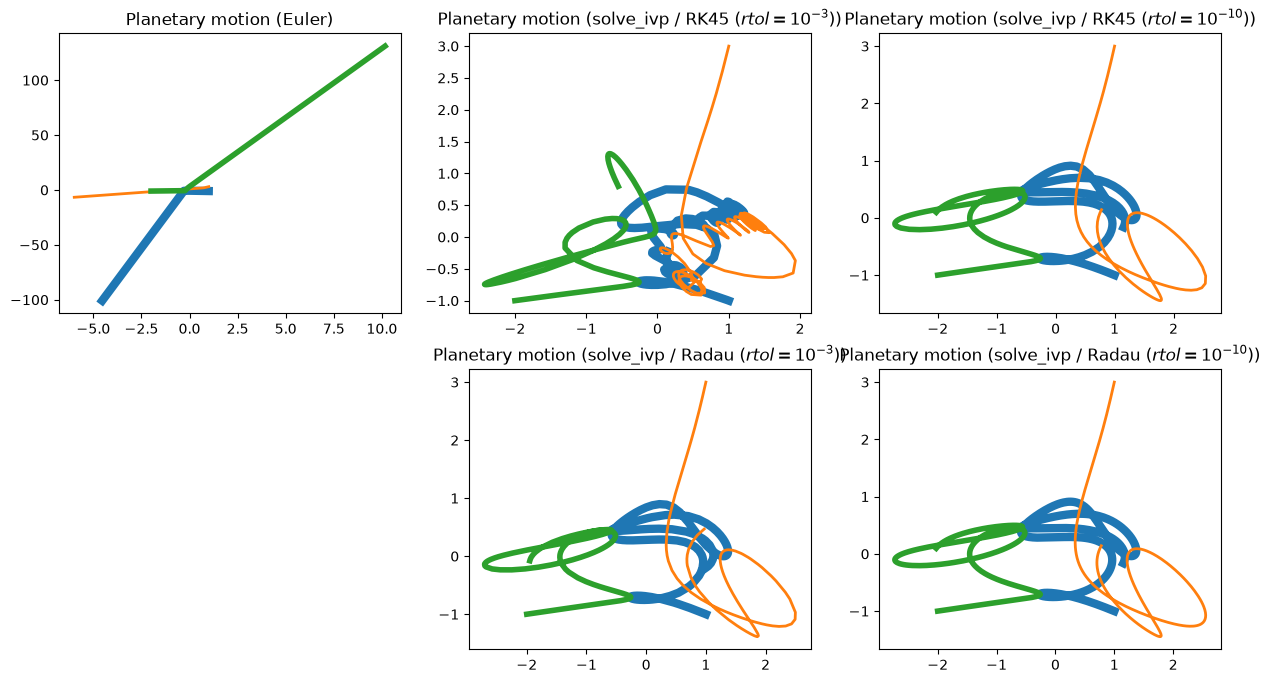

In [47]:
plt.figure(figsize=(15, 8))
figloc = [1, 2, 3, 5, 6]

for fignr, (r, _, _, method) in enumerate(solutions):
    plt.subplot(2, 3, figloc[fignr])
    for ix, m in enumerate(masses):
        plt.plot(r[ix, 0, :], r[ix, 1, :], lw=2*(m-2))
    plt.title(f'Planetary motion ({method})')

- Signficantly different
- Which one is correct?

### Calculation of total energy in systems

$$E_{\text{tot}} = E_{\text{kin}} + E_{\text{pot}} = \frac{1}{2}\sum_j m_j |\vec{v}_j|^2
  - G \sum_{k\neq j}  \frac{m_j \times m_k}{\left|\vec{r}_j-\vec{r}_k
\right|} = \text{const}$$

- Total energy should be conserved (note that potential energy is negative here)
- We can therefore check how close each solution is to the starting energy

In [ ]:
def total_energy(
    r: NDArray[np.float64],
    v: NDArray[np.float64],
    masses: NDArray[np.float64],
    g: float = G_DEFAULT,
) -> NDArray[np.float64]:
    """Calculate the total mechanical energy of the N-body system over time.

    Sums the kinetic energy of each body and the pairwise gravitational
    potential energy at every recorded time step.

    Parameters
    ----------
    r : NDArray[np.float64]
        3D array of body positions with shape ``(n_bodies, n_dim, n_t)``.
    v : NDArray[np.float64]
        3D array of body velocities with shape ``(n_bodies, n_dim, n_t)``.
    masses : NDArray[np.float64]
        1D array of body masses with shape ``(n_bodies,)``.
    g : float
        Gravitational constant with default value G_DEFAULT

    Returns
    -------
    NDArray[np.float64]
        1D array of total energy values at each time step with shape ``(n_t,)``.
    """
    n_bodies, n_dim, n_t = r.shape
    energy = np.zeros(n_t)

    for n in range(n_t):
        for body in range(n_bodies):
            # Add kinetic energy for each body
            energy[n] += (0.5 * masses[body]
                          * v[body, :, n].T @ v[body, :, n])

            # Add potential energy once per unique pair
            for other_body in range(body + 1, n_bodies):
                d = r[other_body, :, n] - r[body, :, n]
                energy[n] -= (g * masses[body] * masses[other_body]
                              * (d.T @ d)**(-0.5))

    return energy

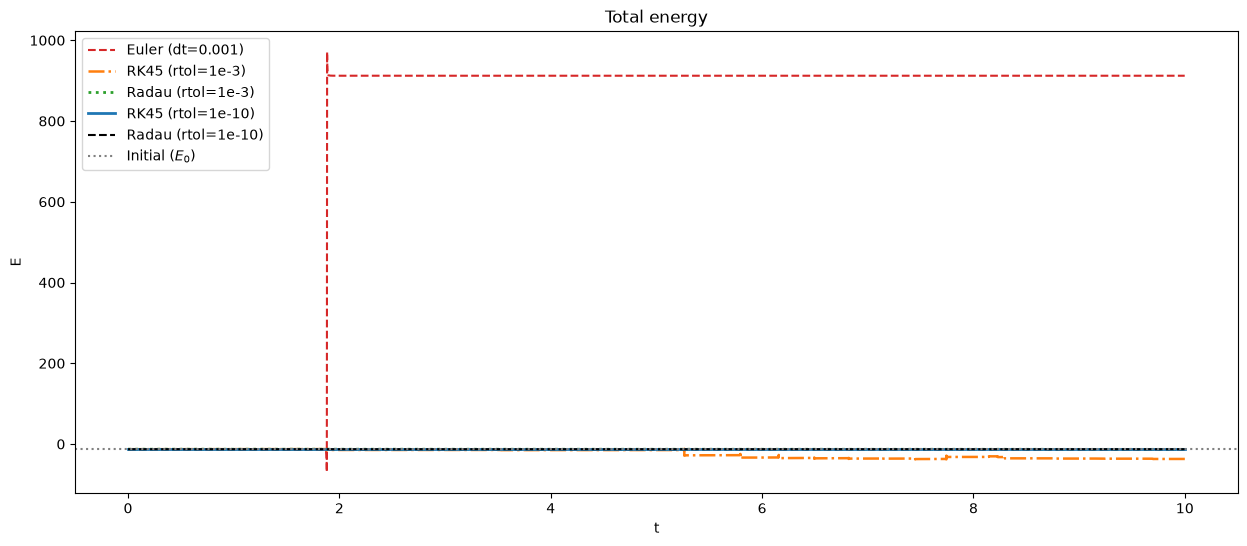

In [60]:
# Make dicts with results and styles for easier plotting
results = {
    'Euler (dt=0.001)':   (r_e, v_e, t_e),
    'RK45 (rtol=1e-3)':   (r_rk45, v_rk45, t_rk45),
    'Radau (rtol=1e-3)':  (r_radau, v_radau, t_radau),
    'RK45 (rtol=1e-10)':  (r_rk45_lt, v_rk45_lt, t_rk45_lt),
    'Radau (rtol=1e-10)': (r_radau_lt, v_radau_lt, t_radau_lt),
}

styles = {
    'Euler (dt=0.001)':   {'color': 'tab:red',    'ls': '--', 'lw': 1.5},
    'RK45 (rtol=1e-3)':   {'color': 'tab:orange', 'ls': '-.', 'lw': 1.8},
    'Radau (rtol=1e-3)':  {'color': 'tab:green',  'ls': ':',  'lw': 2.0},
    'RK45 (rtol=1e-10)':  {'color': 'tab:blue',   'ls': '-',  'lw': 2.0},
    'Radau (rtol=1e-10)': {'color': 'black',      'ls': '--', 'lw': 1.5},
}

plt.figure(figsize=(15, 6))
for name, (r, v, t) in results.items():
    energy = total_energy(r, v, masses)
    plt.plot(t, energy, label=name, **styles[name])
# E0 is energy[0] for all methods, they start out the same
t = [0, 10]  # We set tmax=10 in the methods
plt.axhline(energy[0], color='grey', ls=':', lw=1.5, label='Initial ($E_0$)')
plt.legend()
plt.title('Total energy')
plt.xlabel('t')
plt.ylabel('E')
plt.show()

- The Euler solution clearly struggles
    - The step up happens when the planets makes have the first close encounter
- RK45 with tolerance 1e-3 starts to drift after a while
- We can have a closer look at the energy drift for the different methods

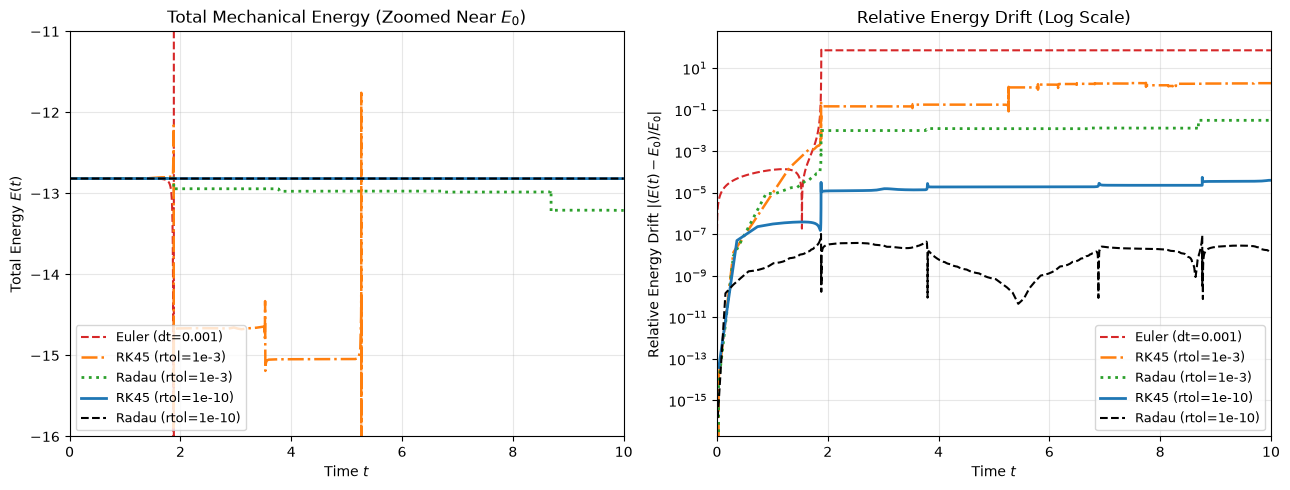

In [62]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for name, (r, v, t) in results.items():
    E = total_energy(r, v, masses)
    rel_drift = np.abs((E - E[0]) / E[0])

    ax1.plot(t, E, label=name, **styles[name])
    # Skip t=0 where rel_drift == 0 to keep the log axis clean
    ax2.semilogy(t[1:], rel_drift[1:], label=name, **styles[name])

# Left panel: Total energy zoomed around E0 ≈ -12.82
ax1.set_xlim(0, 10)
ax1.set_ylim(-16.0, -11.0)
ax1.set_xlabel('Time $t$')
ax1.set_ylabel('Total Energy $E(t)$')
ax1.set_title('Total Mechanical Energy (Zoomed Near $E_0$)')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower left', fontsize=9)

# Right panel: Relative energy drift on a log scale (captures all 5 solvers)
ax2.set_xlim(0, 10)
ax2.set_xlabel('Time $t$')
ax2.set_ylabel(r'Relative Energy Drift $|(E(t) - E_0) / E_0|$')
ax2.set_title('Relative Energy Drift (Log Scale)')
ax2.grid(True, which='both', alpha=0.3)
ax2.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

- Both methods with tolerance 1e-10 are keeping close to $E_0$
- The trajectories obtained with these approaches for $0\leq t \leq 10$ are visually consistent with the scientific literature<br>(Fig 2 of [V. Szebehely and C. F. Peters, Astronom J 72:876–883, 1967](https://articles.adsabs.harvard.edu/pdf/1967AJ.....72..876S))
- We could use further conserved quantities for additional checks
    - center of mass
    - conservation of momentum and angular momentum
- Radau has slightly less energy drift

Code by:
- Hans Ekkehard Plesser (NMBU) - main code
- Turid Torheim (NMBU) - identified and fixed some errors
- Gemini - bug fixes and improved plotting